# BNC2 - Analyses statistiques R1 à R4

Notebook des analyses du nouveau récit (`MYCHOICES.md`, C19 à C24) :

| Bloc | Question |
|---|---|
| **R1** | Combien vaut le service rendu par les forêts (GCW) ? |
| **R2** | Que change l'ajout du bleu (NCW), et comment se place chaque pays face à ses émissions ? |
| **R3** | Quelle part de ce service est détruite par la déforestation ? |
| **R4** | Combien coûterait de compenser cette perte, et qui la supporte ? |

Conventions :

- toutes les incertitudes viennent des 20 000 tirages Monte Carlo du pipeline (C8) ; agrégation **tirage par tirage** ;
- normalisation principale = **ratio au PIB** ; les indicateurs par habitant sont en **annexe** (C22) ;
- les pertes sont la **capacité de séquestration détruite** : surface déboisée FRA × taux Pan × GSCC (C20) ;
- tout point non tranché est marqué `TODO` dans le code.

## 0. Chargement et utilitaires

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "data_source").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data_source", ROOT / "output"
FIG = OUT / "figures" / "notebook"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})

CARBON_TO_CO2 = 44.0 / 12.0
GROUP_ORDER = ["Developed economies", "Developing economies", "LDCs", "SIDS"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
print("racine du dépôt :", ROOT)

racine du dépôt : <user-profile>\Desktop\M2\Stage ecoseas-csm\CSM\BNC2 paper\repo


In [2]:
gcw = pd.read_csv(OUT / "country_level_gcw.csv")
ncw = pd.read_csv(OUT / "country_level_ncw.csv")
terr = pd.read_csv(DATA / "summary" / "territories.csv")
rates = pd.read_csv(DATA / "summary" / "biome_rates.csv").set_index("pan_biome")
area_biome = pd.read_csv(DATA / "summary" / "forest_area_by_biome.csv")

gcw_npz = np.load(OUT / "draws" / "gcw_draws.npz", allow_pickle=True)
ncw_npz = np.load(OUT / "draws" / "ncw_draws.npz", allow_pickle=True)

GSCC = gcw_npz["gscc"].astype("float64")             # (20000,) US$2015 / tCO2
UNITS = ncw_npz["iso3"].astype(str)                   # 266 unités comptables (C12)
D_GCW = ncw_npz["gcw_usd2015_yr"].astype("float64")   # (266, 20000)
D_BCW = ncw_npz["bcw_usd2015_yr"].astype("float64")
D_NCW = ncw_npz["ncw_usd2015_yr"].astype("float64")
N_DRAWS = GSCC.size

# RÈGLE NaN (C27) : une valeur absente reste NaN, jamais 0.
# 0 signifie « mesuré et nul », NaN signifie « on ne sait pas ». Les totaux sont donc des
# `nansum` explicites, accompagnés du nombre d'unités qui y contribuent.
HAS_GCW = ~np.isnan(D_GCW[:, 0])
HAS_BCW = ~np.isnan(D_BCW[:, 0])
HAS_NCW = ~np.isnan(D_NCW[:, 0])
for label, mask in (("GCW", HAS_GCW), ("BCW", HAS_BCW), ("NCW", HAS_NCW)):
    print(f"{label} : {int(mask.sum())} unités renseignées, {int((~mask).sum())} sans donnée (NaN, pas 0)")

print(f"{len(UNITS)} unités, {N_DRAWS} tirages ; GSCC moyen = {GSCC.mean():.1f} US$2015/tCO2")

GCW : 236 unités renseignées, 30 sans donnée (NaN, pas 0)
BCW : 181 unités renseignées, 85 sans donnée (NaN, pas 0)
NCW : 242 unités renseignées, 24 sans donnée (NaN, pas 0)
266 unités, 20000 tirages ; GSCC moyen = 559.6 US$2015/tCO2


In [3]:
def summarise(draws, label="valeur"):
    """Résume une distribution de tirages (moyenne, médiane, sd, p5, p95)."""
    d = np.asarray(draws, dtype="float64")
    return pd.Series({"mean": d.mean(), "p50": np.median(d), "sd": d.std(ddof=1),
                      "p05": np.percentile(d, 5), "p95": np.percentile(d, 95)}, name=label)


def summarise_rows(draws, index, prefix=""):
    """Résume ligne par ligne une matrice (unités x tirages)."""
    d = np.asarray(draws, dtype="float64")
    return pd.DataFrame({f"{prefix}mean": d.mean(axis=1),
                         f"{prefix}p50": np.median(d, axis=1),
                         f"{prefix}sd": d.std(axis=1, ddof=1),
                         f"{prefix}p05": np.percentile(d, 5, axis=1),
                         f"{prefix}p95": np.percentile(d, 95, axis=1)}, index=index)


def usd(x, unit="T"):
    """Formate un montant en US$ (T = trillions, B = milliards, M = millions)."""
    div = {"T": 1e12, "B": 1e9, "M": 1e6}[unit]
    return f"{x / div:,.2f} {unit}$"


def gini(x):
    x = np.sort(np.asarray(x, dtype="float64"))
    x = x[~np.isnan(x)]
    if x.size == 0 or x.sum() == 0:
        return np.nan
    n = x.size
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))


def lorenz_points(x):
    x = np.sort(np.asarray(x, dtype="float64"))
    x = x[~np.isnan(x)]
    return np.linspace(0, 1, x.size + 1), np.concatenate([[0], np.cumsum(x) / x.sum()])


def pairwise_mannwhitney(values_by_group):
    """Comparaisons deux à deux, alternative non paramétrique au post-hoc de Dunn."""
    names = list(values_by_group)
    rows = []
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            u, p = stats.mannwhitneyu(values_by_group[a], values_by_group[b], alternative="two-sided")
            rows.append({"groupe A": a, "groupe B": b, "U": u, "p brut": p})
    out = pd.DataFrame(rows).sort_values("p brut").reset_index(drop=True)
    m = len(out)
    adj = np.maximum.accumulate((m - np.arange(m)) * out["p brut"].to_numpy())
    out["p ajusté (Holm)"] = np.clip(adj, 0, 1)
    return out

### Table de travail

Une ligne par unité comptable (C12), avec groupe, PIB, population, émissions et dette.
Les émissions et la dette viennent de la table BCW publiée : comme la population et le PIB, elles
**ne sont jamais sommées** entre les parties d'un même pays (C12), on prend la valeur de la ligne principale.

In [4]:
bcw_raw = pd.read_csv(DATA / "raw" / "bcw" / "output" / "country_level_bcw.csv")
bcw_raw["ISO"] = bcw_raw["ISO"].astype(str)

code_to_unit = {}
for _, r in terr.dropna(subset=["bcw_codes"]).iterrows():
    for code in str(r["bcw_codes"]).split(";"):
        code_to_unit[code] = r["iso3"]

bcw_raw["unit"] = bcw_raw["ISO"].map(code_to_unit)
socio = (bcw_raw.dropna(subset=["unit"]).sort_values("CO2_emissions_2023", ascending=False)
         .groupby("unit")[["CO2_emissions_2023", "Debt (2015 US$)"]].first()
         .rename(columns={"CO2_emissions_2023": "co2_emissions_tco2_2023",
                          "Debt (2015 US$)": "debt_usd2015"}))

base = (ncw.drop(columns=[c for c in ("continent", "groups", "population", "gdp") if c in ncw.columns])
        .merge(terr[["iso3", "continent", "groups", "population", "gdp"]], on="iso3", how="left")
        .merge(socio, left_on="iso3", right_index=True, how="left"))
base["debt_share_of_gdp"] = 100 * base["debt_usd2015"] / base["gdp"]
print(base.shape, "| unités sans émissions :", int(base["co2_emissions_tco2_2023"].isna().sum()))
base.head(3)

(266, 31) | unités sans émissions : 55


,iso3,name,bcw_codes,fra_region,ncw_usd2015_yr_mean,ncw_usd2015_yr_sd,ncw_usd2015_yr_p05,ncw_usd2015_yr_p50,ncw_usd2015_yr_p95,gcw_usd2015_yr_mean,gcw_usd2015_yr_p05,gcw_usd2015_yr_p95,bcw_usd2015_yr_mean,bcw_usd2015_yr_p05,bcw_usd2015_yr_p95,bcw_published_usd2015_yr_mean,bcw_mangrove_gapfill_usd2015_yr_mean,ncw_alt_mangroves_usd2015_yr_mean,has_gcw,has_bcw,bcw_mangrove_gapfilled,ncw_per_capita_usd2015,ncw_share_of_gdp,forest_share_of_ncw,continent,groups,population,gdp,co2_emissions_tco2_2023,debt_usd2015,debt_share_of_gdp
0,BRA,Brazil,BR-ES;BRA,South America,1.339956e+12,6.855413e+11,5.100186e+11,1.212839e+12,2.576471e+12,1.309535e+12,4.978338e+11,2.522976e+12,3.042104e+10,1.167608e+10,5.896683e+10,3.042104e+10,NaN,1.339400e+12,True,True,False,6346.267807,0.685486,0.977297,Americas,Developing economies,211140729.0,1.954752e+12,4.864701e+08,4.583722e+11,23.449121
1,USA,United States of America,US-AK;US-HI;USA,North and Central America,7.502893e+11,3.641104e+11,2.924226e+11,6.829101e+11,1.382997e+12,5.791934e+11,2.256088e+11,1.075817e+12,1.710958e+11,6.690631e+10,3.104264e+11,1.710958e+11,NaN,7.501310e+11,True,True,False,2184.392349,0.034454,0.771960,Americas,Developed economies,343477335.0,2.177628e+13,4.911391e+09,NaN,NaN
2,RUS,Russian Federation,RUS,Europe,6.874758e+11,3.363964e+11,2.684081e+11,6.261912e+11,1.284221e+12,5.894187e+11,2.293838e+11,1.109575e+12,9.805708e+10,3.829763e+10,1.780425e+11,9.805708e+10,NaN,6.874758e+11,True,True,False,4726.852773,0.450946,0.857367,Europe,Developed economies,145440500.0,1.524520e+12,1.815925e+09,NaN,NaN


**Année de référence socio-économique : 2023**, convention reprise de BCW (méthodes de Hilmi et al. 2026) :

| Variable | Source | Année |
|---|---|---|
| Émissions de CO₂ | Global Carbon Budget 2024 via Our World in Data ; **fossile et industrie, hors usage des terres** | 2023 |
| Dette extérieure totale | Banque mondiale, *External Debt Stocks, Total (DOD)* | 2023 |
| Population | UN WPP 2024 | 2023 |
| PIB | 2023 ou l'année antérieure la plus proche | 2023 |

Deux conséquences :

1. les émissions **excluent le changement d'usage des terres**, donc le bilan net de R2 ne compte pas deux fois la déforestation traitée en R3 ;
2. le flux forestier porte sur 2010–2019 (C4) et les surfaces sont celles de FRA 2025 : le décalage temporel existe déjà et il est documenté comme limite. Aligner les émissions sur une année plus récente que 2023 casserait la cohérence avec la population, le PIB et la dette, sans supprimer ce décalage.

> **TODO (C21)** : reste à obtenir le seuil de tension de dette utilisé dans la Fig. 5c de BCW.

## R1 - Le service rendu par les forêts (GCW)

Question : *combien vaut l'absorption annuelle de CO₂ par les forêts existantes ?*
Méthode : Route B, surface FRA 2025 × parts de biome × taux Pan 2024 × GSCC (C1, C2, C17).

### R1.1 Total mondial, par biome et par groupe

In [5]:
world = pd.concat([summarise(np.nansum(D_GCW, axis=0), "GCW"),
                   summarise(np.nansum(D_BCW, axis=0), "BCW"),
                   summarise(np.nansum(D_NCW, axis=0), "NCW")], axis=1).T
display(world.map(usd))

uptake_world = np.nansum(D_GCW, axis=0) / GSCC   # tirage par tirage, unités renseignées seulement
print("absorption forestière mondiale :",
      f"{uptake_world.mean() / 1e9:.2f} GtCO2/an",
      f"({uptake_world.mean() / CARBON_TO_CO2 / 1e9:.2f} GtC/an)")

,mean,p50,sd,p05,p95
GCW,8.16 T$,7.41 T$,4.09 T$,3.15 T$,15.49 T$
BCW,2.33 T$,2.11 T$,1.13 T$,0.91 T$,4.30 T$
NCW,10.49 T$,9.54 T$,5.17 T$,4.07 T$,19.66 T$


absorption forestière mondiale :

 14.58 GtCO2/an (3.98 GtC/an)


In [6]:
# Par biome : surfaces harmonisées x taux Pan, variante hors mangroves (C7)
ab = area_biome.query("variant == 'excl_mangroves'")
biome = (ab.groupby("pan_biome")["area_ha"].sum().to_frame("area_ha")
         .join(rates[["rate_tc_ha_yr_mean", "rate_tc_ha_yr_sd"]]))
biome["uptake_gtco2_yr"] = biome["area_ha"] * biome["rate_tc_ha_yr_mean"] * CARBON_TO_CO2 / 1e9
biome["gcw_bn_usd_yr"] = biome["uptake_gtco2_yr"] * 1e9 * GSCC.mean() / 1e9
biome["share_%"] = 100 * biome["uptake_gtco2_yr"] / biome["uptake_gtco2_yr"].sum()
display(biome.round(2))

,area_ha,rate_tc_ha_yr_mean,rate_tc_ha_yr_sd,uptake_gtco2_yr,gcw_bn_usd_yr,share_%
pan_biome,,,,,,
boreal,1.135233e+09,0.28,0.03,1.16,649.41,7.95
temperate,6.163773e+08,0.87,0.06,1.96,1095.16,13.41
tropical,2.372981e+09,1.32,0.21,11.48,6423.93,78.64


In [7]:
groups = base.set_index("iso3")["groups"].reindex(UNITS)
rows = {}
for g in GROUP_ORDER:
    mask = (groups == g).to_numpy()
    tot = np.nansum(D_GCW[mask], axis=0)
    rows[g] = {"n": int(mask.sum()), **summarise(tot).to_dict(),
               "avec GCW": int((mask & HAS_GCW).sum()),
               "part du monde (%)": 100 * tot.mean() / np.nansum(D_GCW, axis=0).mean()}
tab_group = pd.DataFrame(rows).T
display(tab_group.assign(**{c: tab_group[c].map(usd) for c in ["mean", "p50", "sd", "p05", "p95"]}))

,n,mean,p50,sd,p05,p95,avec GCW,part du monde (%)
Developed economies,68.0,2.26 T$,2.06 T$,1.10 T$,0.88 T$,4.18 T$,60.0,27.722606
Developing economies,88.0,4.19 T$,3.80 T$,2.14 T$,1.60 T$,8.04 T$,80.0,51.400790
LDCs,37.0,1.47 T$,1.33 T$,0.76 T$,0.56 T$,2.84 T$,37.0,18.079052
SIDS,57.0,0.23 T$,0.21 T$,0.12 T$,0.09 T$,0.44 T$,57.0,2.794996


### R1.2 Poids économique : ratio GCW/PIB (normalisation principale, C22)

In [8]:
r1 = base.dropna(subset=["gcw_usd2015_yr_mean"]).copy()
r1["gcw_share_of_gdp"] = 100 * r1["gcw_usd2015_yr_mean"] / r1["gdp"]
print("GCW mondial / PIB mondial :",
      f"{100 * r1['gcw_usd2015_yr_mean'].sum() / r1['gdp'].sum():.1f} %")
display(r1.nlargest(15, "gcw_share_of_gdp")[["name", "groups", "gcw_usd2015_yr_mean", "gcw_share_of_gdp"]]
        .assign(gcw_usd2015_yr_mean=lambda d: d["gcw_usd2015_yr_mean"].map(lambda v: usd(v, "B"))).round(1))
display(r1.groupby("groups")["gcw_share_of_gdp"].describe()[["count", "50%", "mean", "max"]].round(1))

GCW mondial / PIB mondial : 8.9 %


,name,groups,gcw_usd2015_yr_mean,gcw_share_of_gdp
20,Central African Republic,LDCs,121.84 B$,5936.4
45,Suriname,SIDS,39.43 B$,875.2
5,Democratic Republic of the Congo,LDCs,376.00 B$,661.5
32,Congo,Developing economies,59.04 B$,569.4
68,Liberia,LDCs,17.06 B$,475.3
21,Zambia,LDCs,121.24 B$,437.5
71,Solomon Islands,SIDS,6.72 B$,432.6
26,Mozambique,LDCs,86.14 B$,421.5
29,Gabon,Developing economies,63.13 B$,389.3
14,Bolivia (Plurinational State of),Developing economies,146.90 B$,374.2


,count,50%,mean,max
groups,,,,
Developed economies,53.0,2.7,6.9,38.7
Developing economies,67.0,10.5,50.0,569.4
LDCs,34.0,75.1,297.1,5936.4
SIDS,49.0,6.2,65.0,875.2


### R1.3 Concentration : Lorenz, Gini, part des dix premiers

Gini du GCW entre pays : 0.856
Part des 10 premiers pays : 57.4 %


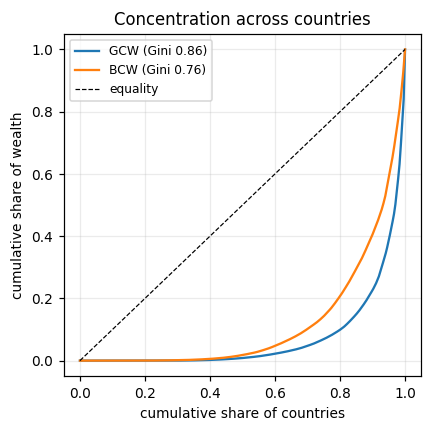

,name,groups,gcw_usd2015_yr_mean,gcw_share_of_gdp
0,Brazil,Developing economies,"1,309.53 B$",67.0
2,Russian Federation,Developed economies,589.42 B$,38.7
1,United States of America,Developed economies,579.19 B$,2.7
3,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Developing economies,533.17 B$,3.1
5,Democratic Republic of the Congo,LDCs,376.00 B$,661.5
4,Australia,Developed economies,342.91 B$,21.0
6,Canada,Developed economies,327.70 B$,18.4
7,Indonesia,Developing economies,250.09 B$,21.2
9,India,Developing economies,195.16 B$,6.1
8,Peru,Developing economies,181.43 B$,81.8


In [9]:
vals = r1["gcw_usd2015_yr_mean"].to_numpy()
top10 = r1.nlargest(10, "gcw_usd2015_yr_mean")
print(f"Gini du GCW entre pays : {gini(vals):.3f}")
print(f"Part des 10 premiers pays : {100 * top10['gcw_usd2015_yr_mean'].sum() / vals.sum():.1f} %")

fig, ax = plt.subplots(figsize=(4, 4))
x, y = lorenz_points(vals)
ax.plot(x, y, label=f"GCW (Gini {gini(vals):.2f})")
bcw_vals = base["bcw_usd2015_yr_mean"].dropna().to_numpy()
xb, yb = lorenz_points(bcw_vals)
ax.plot(xb, yb, label=f"BCW (Gini {gini(bcw_vals):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="equality")
ax.set_xlabel("cumulative share of countries"); ax.set_ylabel("cumulative share of wealth")
ax.set_title("Concentration across countries"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "R1_lorenz.png"); plt.show()

display(top10[["name", "groups", "gcw_usd2015_yr_mean", "gcw_share_of_gdp"]]
        .assign(gcw_usd2015_yr_mean=lambda d: d["gcw_usd2015_yr_mean"].map(lambda v: usd(v, "B"))).round(1))

### R1.4 Dotation écologique contre taille économique (commentaire des coauteurs n°16)

Spearman GCW ~ PIB : rho = 0.55 (p = 7.7e-17, n = 198)


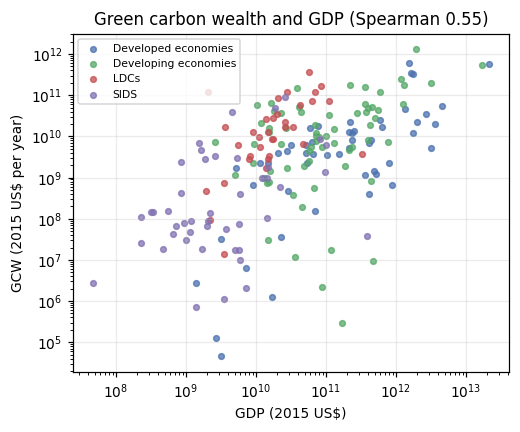

In [10]:
sub = r1.dropna(subset=["gdp"]).query("gdp > 0 and gcw_usd2015_yr_mean > 0")
rho, p = stats.spearmanr(sub["gcw_usd2015_yr_mean"], sub["gdp"])
print(f"Spearman GCW ~ PIB : rho = {rho:.2f} (p = {p:.1e}, n = {len(sub)})")

fig, ax = plt.subplots(figsize=(4.8, 4))
for g, d in sub.groupby("groups"):
    ax.scatter(d["gdp"], d["gcw_usd2015_yr_mean"], s=14, alpha=0.75, label=g,
               color=GROUP_COLORS.get(g, "grey"))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("GDP (2015 US$)"); ax.set_ylabel("GCW (2015 US$ per year)")
ax.set_title(f"Green carbon wealth and GDP (Spearman {rho:.2f})"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R1_gcw_vs_gdp.png"); plt.show()

### R1.5 Les groupes diffèrent-ils ? (Kruskal-Wallis puis comparaisons deux à deux)

In [11]:
vals_by_group = {g: r1.loc[r1["groups"] == g, "gcw_share_of_gdp"].dropna().to_numpy() for g in GROUP_ORDER}
vals_by_group = {g: v for g, v in vals_by_group.items() if v.size > 2}
h, p = stats.kruskal(*vals_by_group.values())
print(f"Kruskal-Wallis sur GCW/PIB : H = {h:.1f}, p = {p:.2e}")
display(pairwise_mannwhitney(vals_by_group).round(4))

Kruskal-Wallis sur GCW/PIB : H = 48.1, p = 2.02e-10


,groupe A,groupe B,U,p brut,p ajusté (Holm)
0,Developed economies,LDCs,133.0,0.0000,0.0000
1,Developing economies,LDCs,516.0,0.0000,0.0000
2,LDCs,SIDS,1308.0,0.0000,0.0000
3,Developed economies,Developing economies,1069.0,0.0002,0.0006
4,Developed economies,SIDS,1027.0,0.0695,0.1390
5,Developing economies,SIDS,1900.0,0.1493,0.1493


### R1.6 Stabilité des rangs sous incertitude

Probabilité, sur les 20 000 tirages, qu'un pays figure dans les dix premiers.
Les taux de biome étant partagés par tous les pays (C15), les rangs ne bougent qu'entre pays de biomes différents.

In [12]:
order = np.argsort(-np.nan_to_num(D_GCW, nan=-np.inf), axis=0)   # les NaN ne peuvent pas entrer au classement
counts = np.zeros(len(UNITS))
np.add.at(counts, order[:10].ravel(), 1)
prob = pd.Series(counts / N_DRAWS, index=UNITS, name="P(top 10)")
names = base.set_index("iso3")["name"]
display(prob[prob > 0].sort_values(ascending=False).to_frame().join(names).head(15).round(3))

,P(top 10),name
AUS,1.0,Australia
BRA,1.0,Brazil
CHN,1.0,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)"
COD,1.0,Democratic Republic of the Congo
IDN,1.0,Indonesia
IND,1.0,India
PER,1.0,Peru
RUS,1.0,Russian Federation
USA,1.0,United States of America
CAN,1.0,Canada


> **Pas de régression du GCW sur la surface ou les biomes** : le GCW est construit comme surface × taux,
> une telle régression serait tautologique (C23).

## R2 - De GCW à NCW

Deux questions : de quoi est faite la richesse carbone de chaque pays, verte ou bleue,
et où se situe chaque pays face à ses propres émissions.

### R2.1 Composition verte / bleue

composition calculable pour 175 unités sur 242


profil,mixte,à dominante bleue,à dominante verte
groups,,,
Developed economies,5,11,21
Developing economies,14,16,30
LDCs,5,1,15
SIDS,14,33,10


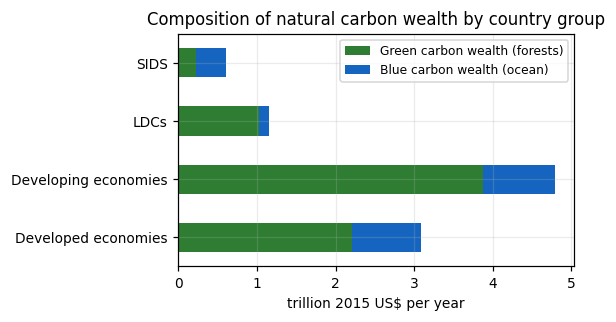

In [13]:
comp = base.dropna(subset=["ncw_usd2015_yr_mean"]).copy()
# composition calculée uniquement là où les deux composantes sont connues (C27)
comp = comp[comp["has_gcw"] & comp["has_bcw"]].copy()
print(f"composition calculable pour {len(comp)} unités sur {int(base['ncw_usd2015_yr_mean'].notna().sum())}")
comp["forest_share"] = 100 * comp["gcw_usd2015_yr_mean"] / comp["ncw_usd2015_yr_mean"]
THRESHOLD = 66.7   # TODO (C21) : seuil de classification à valider
comp["profil"] = np.select([comp["forest_share"] >= THRESHOLD, comp["forest_share"] <= 100 - THRESHOLD],
                           ["à dominante verte", "à dominante bleue"], default="mixte")
display(pd.crosstab(comp["groups"], comp["profil"]))

fig, ax = plt.subplots(figsize=(5.4, 3))
agg = comp.groupby("groups")[["gcw_usd2015_yr_mean", "bcw_usd2015_yr_mean"]].sum().reindex(GROUP_ORDER) / 1e12
agg.plot(kind="barh", stacked=True, ax=ax, color=["#2E7D32", "#1565C0"])
ax.set_xlabel("trillion 2015 US$ per year"); ax.set_ylabel("")
ax.legend(["Green carbon wealth (forests)", "Blue carbon wealth (ocean)"], fontsize=8)
ax.set_title("Composition of natural carbon wealth by country group")
fig.tight_layout(); fig.savefig(FIG / "R2_composition.png"); plt.show()

### R2.2 Bilan net de CO₂ : forêt seule puis forêt + océan

Reprise de la Fig. 5a de BCW, étendue au vert (C21). Le bilan net d'un pays est
`séquestration comptabilisée − émissions nationales de CO₂`.

unités avec émissions renseignées : 211 ; bilan calculable pour 210
puits nets — forêt seule : 37 % | forêt + océan : 52 %


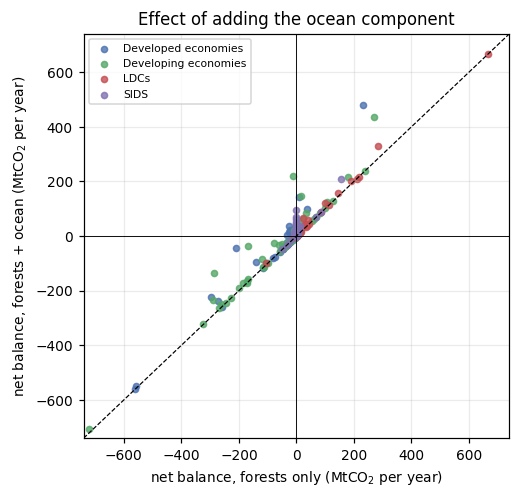

In [ ]:
emis = base.set_index("iso3")["co2_emissions_tco2_2023"].reindex(UNITS).to_numpy()
seq_gcw = D_GCW / GSCC          # tCO2/an, tirage par tirage
seq_ncw = D_NCW / GSCC
bal_gcw = seq_gcw - emis[:, None]
bal_ncw = seq_ncw - emis[:, None]
ok = ~np.isnan(emis)

balance = pd.DataFrame({"iso3": UNITS,
                        "bal_gcw": bal_gcw.mean(axis=1), "bal_ncw": bal_ncw.mean(axis=1),
                        "p_sink_gcw": (bal_gcw > 0).mean(axis=1),
                        "p_sink_ncw": (bal_ncw > 0).mean(axis=1)})
balance = (balance[ok].dropna(subset=["bal_gcw", "bal_ncw"])   # NaN = composante inconnue (C27)
           .merge(base[["iso3", "name", "groups", "debt_share_of_gdp", "gdp"]], on="iso3"))

print(f"unités avec émissions renseignées : {int(ok.sum())} ; bilan calculable pour {len(balance)}")
print(f"puits nets - forêt seule : {100 * (balance['bal_gcw'] > 0).mean():.0f} %"
      f" | forêt + océan : {100 * (balance['bal_ncw'] > 0).mean():.0f} %")

fig, ax = plt.subplots(figsize=(4.8, 4.6))
for g, d in balance.groupby("groups"):
    ax.scatter(d["bal_gcw"] / 1e6, d["bal_ncw"] / 1e6, s=16, alpha=0.8,
               color=GROUP_COLORS.get(g, "grey"), label=g)
lim = np.nanpercentile(np.abs(balance[["bal_gcw", "bal_ncw"]].to_numpy()) / 1e6, 97)
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("net balance, forests only (MtCO$_2$ per year)")
ax.set_ylabel("net balance, forests + ocean (MtCO$_2$ per year)")
ax.set_title("Effect of adding the ocean component"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R2_balance_1to1.png"); plt.show()

### R2.3 Quadrants : bilan net et tension de dette (Fig. 5c de BCW)

Axe vertical : bilan net de CO₂, seuil 0 entre puits nets et sources.
Axe horizontal : dette rapportée au PIB, seuil de tension `DEBT_THRESHOLD`.

quadrant,puits net / dette faible,puits net / dette élevée,source nette / dette faible,source nette / dette élevée
groups,,,,
Developed economies,0,1,3,4
Developing economies,20,3,22,7
LDCs,24,6,2,2
SIDS,14,5,3,1


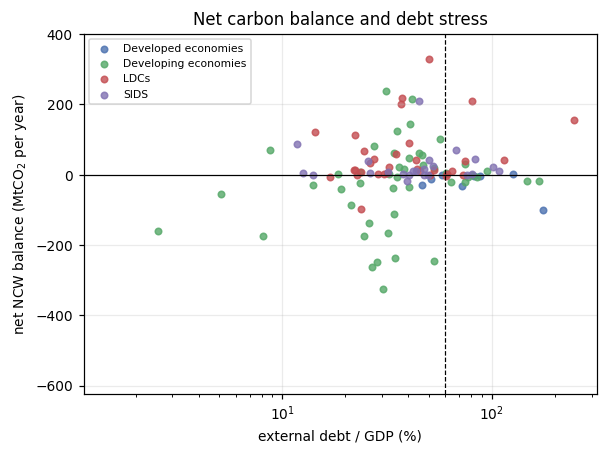

In [15]:
DEBT_THRESHOLD = 60.0   # TODO (C21) : reprendre le seuil exact de la Fig. 5c de BCW

q = balance.dropna(subset=["debt_share_of_gdp"]).copy()
q["position carbone"] = np.where(q["bal_ncw"] > 0, "puits net", "source nette")
q["position dette"] = np.where(q["debt_share_of_gdp"] > DEBT_THRESHOLD, "dette élevée", "dette faible")
q["quadrant"] = q["position carbone"] + " / " + q["position dette"]
display(pd.crosstab(q["groups"], q["quadrant"]))

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for g, d in q.groupby("groups"):
    ax.scatter(d["debt_share_of_gdp"], d["bal_ncw"] / 1e6, s=18, alpha=0.8,
               color=GROUP_COLORS.get(g, "grey"), label=g)
for _, row in q.reindex(q["bal_ncw"].abs().nlargest(6).index).iterrows():
    ax.annotate(row["iso3"], (row["debt_share_of_gdp"], row["bal_ncw"] / 1e6), fontsize=7)
ax.axhline(0, color="k", lw=0.8); ax.axvline(DEBT_THRESHOLD, color="k", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_ylim(np.nanpercentile(q["bal_ncw"] / 1e6, 2), np.nanpercentile(q["bal_ncw"] / 1e6, 98))
ax.set_xlabel("external debt / GDP (%)"); ax.set_ylabel("net NCW balance (MtCO$_2$ per year)")
ax.set_title("Net carbon balance and debt stress"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R2_quadrants.png"); plt.show()

### R2.4 Figure en barres : émissions vers le haut, séquestration vers le bas

Choix du 2026-09-20 (C21) : la grandeur est le **NCW**, la barre descendante distingue vert et bleu.
La part déjà détruite par la déforestation est ajoutée en R3, pour que la figure dise quelque chose
que la Fig. 5 de BCW ne disait pas.

**Lecture de la figure** (textes en anglais, comme toutes les figures du papier) :

- **moitié gauche** : les dix plus gros émetteurs, classés du plus gros au plus petit ;
- **moitié droite** : les dix plus grosses séquestrations parmi les autres pays, classées en ordre croissant,
  donc la plus grosse est tout à droite. La figure dessine ainsi un « V » : émissions à gauche, puits à droite ;
- **largeur des barres** : `WIDTH_METRIC` pilote cette dimension.
  - `"equal"` (retenu ici) : largeurs égales, hauteurs = totaux nationaux en MtCO₂/an ;
  - `"population"` : largeur proportionnelle à la population, hauteurs **par habitant**, donc l'**aire** vaut
    le total national (diagramme de Marimekko). Testé : la Chine, l'Inde et les États-Unis écrasent les autres
    barres et les étiquettes deviennent illisibles, cette version est donc reléguée en annexe ;
  - `"gdp"` : largeur proportionnelle au PIB, hauteurs = intensité carbone ;
- **couleurs** : une seule couleur pour toute la séquestration ; le carbone bleu est distingué par des hachures.

**Unités** : tout est en tonnes de CO₂ par an. L'absorption forestière vient directement de la colonne
physique `uptake_tco2_yr_mean` du pipeline, sans passer par les dollars. Pour le BCW, aucune colonne physique
n'est publiée : on divise les tirages de valeur par les tirages de GSCC, ce qui redonne exactement les tCO₂.

gauche : CHN, USA, IND, RUS, JPN, IRN, SAU, IDN, DEU, KOR
droite : ARG, CHL, COL, AGO, MEX, PER, CAN, COD, AUS, BRA


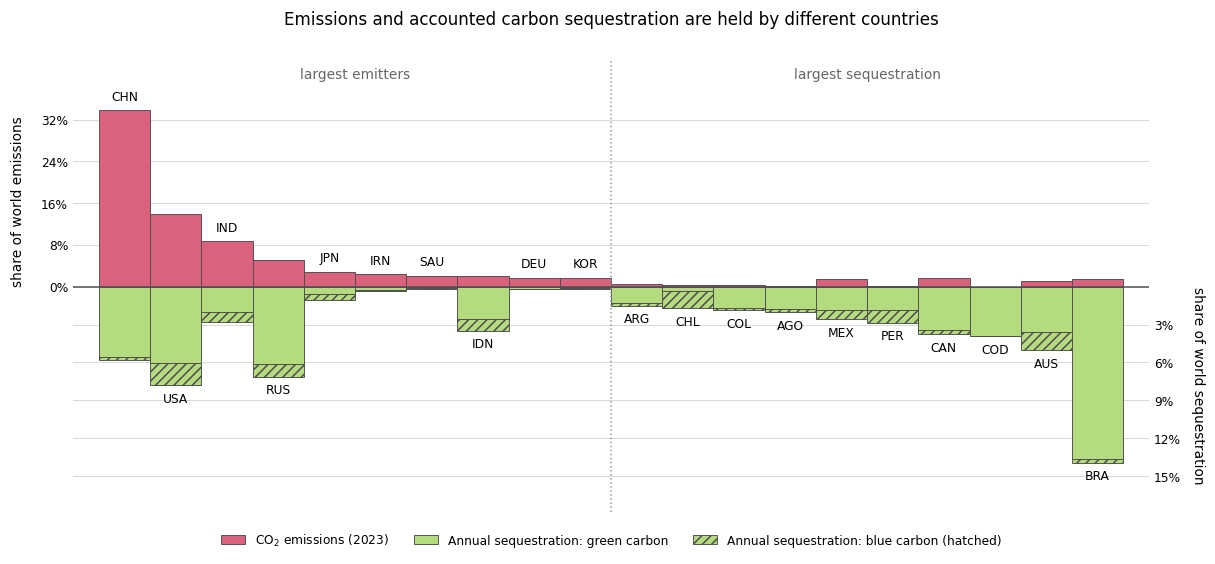

les 10 premiers émetteurs = 74 % des émissions mondiales
les 10 premières séquestrations = 39 % de la séquestration comptabilisée


In [ ]:
TOP_N = 10                  # pays retenus de chaque côté
WIDTH_METRIC = "equal"      # "equal", "population" ou "gdp" - voir la note sous la figure

bcw_tco2 = pd.Series((D_BCW / GSCC).mean(axis=1), index=UNITS, name="seq_bcw")

panel_src = (base[["iso3", "name", "groups", "co2_emissions_tco2_2023", "population", "gdp"]]
             .merge(gcw[["iso3", "uptake_tco2_yr_mean"]], on="iso3", how="left")
             .merge(bcw_tco2, left_on="iso3", right_index=True, how="left")
             .rename(columns={"uptake_tco2_yr_mean": "seq_gcw"})
             .dropna(subset=["co2_emissions_tco2_2023", "population", "seq_gcw", "seq_bcw"]))
panel_src["seq_total"] = panel_src["seq_gcw"] + panel_src["seq_bcw"]

# moitié gauche : plus gros émetteurs, décroissant ; moitié droite : plus grosse séquestration, croissant
left = panel_src.nlargest(TOP_N, "co2_emissions_tco2_2023").sort_values(
    "co2_emissions_tco2_2023", ascending=False)
right = (panel_src[~panel_src["iso3"].isin(left["iso3"])]
         .nlargest(TOP_N, "seq_total").sort_values("seq_total"))
panel = pd.concat([left, right], ignore_index=True)
print(f"gauche : {', '.join(left['iso3'])}")
print(f"droite : {', '.join(right['iso3'])}")


EMIS_COLOR, SEQ_COLOR = "#da627d", "#b4dc7f"
EDGE = "#4d4d4d"

WORLD_EMIS = panel_src["co2_emissions_tco2_2023"].sum()
WORLD_SEQ = panel_src["seq_total"].sum()


def bar_updown(df, mode="share", stretch=True, width_metric=WIDTH_METRIC,
               fname="R2_bars_updown.png"):
    """Barres montantes = émissions, descendantes = séquestration.

    mode="share"    : chaque barre est une part du total mondial correspondant (%).
    mode="absolute" : totaux nationaux en MtCO2/an.
    stretch=True    : la moitié basse a sa propre échelle, pour que la plus grande séquestration
                      atteigne la même profondeur que la plus grande émission. Les graduations du
                      haut se lisent à gauche, celles du bas à droite.
    width_metric    : "equal" ; "population"/"gdp" pour un diagramme de Marimekko ;
                      "erosion" pour une largeur proportionnelle à l'intensité d'érosion (R3).
    """
    df = df.copy()
    if width_metric == "equal":
        widths, denom = np.ones(len(df)), np.ones(len(df))
    elif width_metric == "erosion":
        # largeur = intensité d'érosion (part du GCW national détruite chaque année).
        # Les pays sans déclaration de déforestation sortent du panneau : une largeur minimale
        # les ferait passer pour peu érodés (C26, C27).
        rate = df["iso3"].map(erosion_rate)
        dropped = df.loc[rate.isna(), "iso3"].tolist()
        if dropped:
            print("exclus, érosion non déclarée :", ", ".join(dropped))
        df = df[rate.notna()].copy()
        rate = rate.dropna().to_numpy()
        widths = 0.35 + 0.65 * (rate - rate.min()) / (rate.max() - rate.min())
        denom = np.ones(len(df))
    else:
        col = "population" if width_metric == "population" else "gdp"
        widths = df[col].to_numpy(dtype="float64")
        denom = widths
    widths = widths / widths.sum() * len(df)
    centres = np.cumsum(widths) - widths / 2

    emis = df["co2_emissions_tco2_2023"].to_numpy() / denom
    gcw_h = df["seq_gcw"].to_numpy() / denom
    bcw_h = df["seq_bcw"].to_numpy() / denom
    if mode == "share":
        emis, gcw_h, bcw_h = (100 * v / w for v, w in
                              ((emis, WORLD_EMIS), (gcw_h, WORLD_SEQ), (bcw_h, WORLD_SEQ)))
        unit, fmt = "%", "{:.0f}%"
    else:
        emis, gcw_h, bcw_h = (v / 1e6 for v in (emis, gcw_h, bcw_h))
        unit, fmt = "MtCO$_2$", "{:,.0f}"
    seq_h = gcw_h + bcw_h
    k = emis.max() / seq_h.max() if stretch else 1.0

    fig, ax = plt.subplots(figsize=(11, 5.2))
    bar = dict(width=widths, edgecolor=EDGE, linewidth=0.6)   # barres jointives
    ax.bar(centres, emis, color=EMIS_COLOR, label="CO$_2$ emissions (2023)", **bar)
    ax.bar(centres, -gcw_h * k, color=SEQ_COLOR, label="Annual sequestration: green carbon", **bar)
    ax.bar(centres, -bcw_h * k, bottom=-gcw_h * k, color=SEQ_COLOR, hatch="////",
           label="Annual sequestration: blue carbon (hatched)", **bar)
    span = max(emis.max(), (seq_h * k).max())
    ax.set_ylim(-span * 1.28, span * 1.28)
    ax.axhline(0, color=EDGE, lw=1.0)

    # étiquettes pays, horizontales, au bout de la barre dominante
    for c, e_, s_ in zip(centres, emis, seq_h * k):
        if e_ >= s_:
            ax.text(c, e_ + span * 0.04, "", ha="center")
    for c, iso, e_, s_ in zip(centres, df["iso3"], emis, seq_h * k):
        if e_ >= s_:
            ax.text(c, e_ + span * 0.04, iso, ha="center", va="bottom", fontsize=8)
        else:
            ax.text(c, -s_ - span * 0.04, iso, ha="center", va="top", fontsize=8)

    # graduations : émissions à gauche, séquestration à droite, avec leur propre échelle
    step = max(round(span / 4, 0), 1)
    up_ticks = np.arange(0, span + step / 2, step)
    ax.set_yticks(up_ticks)
    ax.set_yticklabels([fmt.format(v) for v in up_ticks], fontsize=8)
    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim())
    down_step = max(round(span / k / 4, 0), 1)
    down_ticks = np.arange(down_step, span / k + down_step / 2, down_step)
    ax2.set_yticks(-down_ticks * k)
    ax2.set_yticklabels([fmt.format(v) for v in down_ticks], fontsize=8)

    for a in (ax, ax2):
        for side in ("top", "right", "left", "bottom"):
            a.spines[side].set_visible(False)
        a.tick_params(length=0)
        a.grid(False)
    # grille horizontale des deux côtés de zéro, aux graduations réellement affichées
    for y in np.concatenate([up_ticks[1:], -down_ticks * k]):
        ax.axhline(y, color="#cccccc", lw=0.6, alpha=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xticks([])
    ax.set_xlim(-0.5, widths.sum() + 0.5)
    
    split = widths[:TOP_N].sum()
    ax.axvline(split, color="#999999", ls=":", lw=1.0)
    ax.text(split / 2, span * 1.18, "largest emitters", ha="center", fontsize=9, color="#666666")
    ax.text(split + (widths.sum() - split) / 2, span * 1.18, "largest sequestration",
            ha="center", fontsize=9, color="#666666")
    ax.set_ylabel("share of world emissions" if mode == "share" else f"emissions ({unit}/yr)",
                  fontsize=9, ha="left")
    ax2.set_ylabel("share of world sequestration" if mode == "share" else f"sequestration ({unit}/yr)",
                   fontsize=9, rotation=270, ha="left")
    # les deux intitulés partent de la ligne zéro : celui de gauche monte, celui de droite descend
    zero_frac = (0 - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
    ax.yaxis.set_label_coords(-0.045, zero_frac)
    ax2.yaxis.set_label_coords(1.052, zero_frac)
    ax.set_title("Emissions and accounted carbon sequestration are held by different countries",
                 fontsize=11, pad=24)
    ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=160); plt.show()


bar_updown(panel)
print(f"les {TOP_N} premiers émetteurs = {100 * left['co2_emissions_tco2_2023'].sum() / WORLD_EMIS:.0f} %"
      " des émissions mondiales")
print(f"les {TOP_N} premières séquestrations = {100 * right['seq_total'].sum() / WORLD_SEQ:.0f} %"
      " de la séquestration comptabilisée")

## R3 - L'érosion du service (C20)

Les pertes du papier sont la **capacité de séquestration détruite** : chaque hectare déboisé retire
définitivement l'absorption annuelle qu'il produisait. Le calcul reste celui du GCW :
surface déboisée FRA `1d_deforestation` × taux Pan du biome × 44/12 × GSCC.

### R3.1 Surfaces déboisées (FRA 2025)

In [17]:
with zipfile.ZipFile(DATA / "raw" / "fra" / "fra2025_bulk_WO.zip") as z:
    name = [n for n in z.namelist() if "1d_deforestation" in n][0]
    defor = pd.read_csv(z.open(name))

INTERVALS = ["1990-2000", "2000-2010", "2010-2015", "2015-2020", "2020-2025"]
defor = defor.dropna(subset=["iso3"]).copy()
for c in INTERVALS:
    defor[c] = pd.to_numeric(defor[c], errors="coerce")

# période écologique du GCW (C4) : moyenne des deux intervalles couvrant 2010-2019
defor["defor_kha_yr"] = defor[["2010-2015", "2015-2020"]].mean(axis=1)
defor = defor[["iso3", "name", "defor_kha_yr"] + INTERVALS]
print(f"monde 2010-2019 : {defor['defor_kha_yr'].sum() / 1000:.2f} Mha déboisés par an")
display(defor.nlargest(10, "defor_kha_yr")[["name", "defor_kha_yr"]].round(1))

# Couverture : tous les pays ne déclarent pas la déforestation à FRA
cov = gcw[["iso3", "gcw_usd2015_yr_mean"]].merge(defor[["iso3", "defor_kha_yr"]], on="iso3", how="left")
has = cov["defor_kha_yr"].notna()
print(f"unités FRA avec déforestation déclarée : {int(has.sum())} / {len(cov)}")
print(f"part du GCW mondial couverte : {100 * cov.loc[has, 'gcw_usd2015_yr_mean'].sum() / cov['gcw_usd2015_yr_mean'].sum():.1f} %")
print("plus gros GCW sans déclaration :",
      ", ".join(cov[~has].nlargest(8, "gcw_usd2015_yr_mean")["iso3"]))

monde 2010-2019 : 9.70 Mha déboisés par an


,name,defor_kha_yr
29,Brazil,2272.1
97,India,665.1
56,Democratic Republic of the Congo,645.2
98,Indonesia,541.1
5,Angola,510.4
12,Australia,444.7
223,United Republic of Tanzania,436.0
43,China,331.9
163,Paraguay,307.6
201,Sudan,268.3


unités FRA avec déforestation déclarée : 139 / 236
part du GCW mondial couverte : 78.9 %
plus gros GCW sans déclaration : USA, PER, BOL, ZMB, MMR, ZAF, JPN, THA


### R3.2 Capacité détruite et sa valeur

Les hectares déboisés sont répartis entre biomes avec les parts de biome du pays (C2).
**Hypothèse** : la déforestation suit la composition en biomes du pays, alors qu'elle est surtout tropicale.
Sans effet pour les pays d'un seul biome, à documenter dans les limites.

Les taux sont tirés avec la même loi que le pipeline (normale tronquée à 0, C15), mais avec une graine propre
au notebook : ces tirages ne sont donc **pas corrélés** à ceux du GCW.
`TODO` : déplacer ce calcul dans le pipeline pour partager les mêmes tirages.

In [18]:
shares = (area_biome.query("variant == 'excl_mangroves'")
          .pivot_table(index="iso3", columns="pan_biome", values="area_ha", aggfunc="sum").fillna(0.0))
shares = shares.div(shares.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

rng = np.random.default_rng(20260920)
biomes = list(shares.columns)
rate_draws = np.vstack([np.clip(rng.normal(rates.loc[b, "rate_tc_ha_yr_mean"],
                                           rates.loc[b, "rate_tc_ha_yr_sd"], N_DRAWS), 0, None)
                        for b in biomes])                 # (n_biomes, 20000)

defor_ha = (defor.set_index("iso3")["defor_kha_yr"] * 1000).reindex(shares.index)
reported = defor_ha.notna().to_numpy()                    # unités déclarant leur déforestation
REPORTED_UNITS = np.isin(UNITS, shares.index[reported])   # même masque, aligné sur UNITS
area_by_biome = shares.mul(defor_ha.fillna(0.0), axis=0).to_numpy()   # (n_pays, n_biomes) ha/an
loss_tco2 = (area_by_biome @ rate_draws) * CARBON_TO_CO2  # (n_pays, 20000)
loss_usd = loss_tco2 * GSCC

loss = (summarise_rows(loss_usd, shares.index, prefix="loss_usd_")
        .join(summarise_rows(loss_tco2, shares.index, prefix="loss_tco2_")[["loss_tco2_mean"]]))
loss.index.name = "iso3"
# Les unités sans déclaration deviennent NaN : un zéro les lirait comme « pas de déforestation »,
# ce qui est faux pour le Pérou, la Bolivie ou le Myanmar. Les totaux ne portent donc que sur
# les pays déclarants, et le texte doit annoncer cette couverture.
loss.loc[~reported, :] = np.nan
print("monde, capacité détruite chaque année :",
      f"{np.nansum(loss_tco2, axis=0).mean() / 1e6:.1f} MtCO2/an |",
      usd(np.nansum(loss_usd, axis=0).mean(), "B"), "de GCW par an")
print(f"(total sur les {int(reported.sum())} unités déclarantes ; les autres sont absentes, pas nulles)")

monde, capacité détruite chaque année : 45.9 MtCO2/an | 25.70 B$ de GCW par an
(total sur les 139 unités déclarantes ; les autres sont absentes, pas nulles)


### R3.3 Part érodée, par pays et par groupe

In [19]:
r3 = base[["iso3", "name", "groups", "gdp", "gcw_usd2015_yr_mean"]].merge(
    loss.reset_index(), on="iso3", how="left")
r3["erosion_%_du_gcw"] = 100 * r3["loss_usd_mean"] / r3["gcw_usd2015_yr_mean"]
r3["loss_share_of_gdp"] = 100 * r3["loss_usd_mean"] / r3["gdp"]

covered = r3["loss_usd_mean"].notna()
print("érosion, pays déclarants seulement :",
      f"{100 * r3.loc[covered, 'loss_usd_mean'].sum() / r3.loc[covered, 'gcw_usd2015_yr_mean'].sum():.2f} %"
      " du GCW de ces pays, par an")
print(f"couverture : {int(covered.sum())} unités, soit "
      f"{100 * r3.loc[covered, 'gcw_usd2015_yr_mean'].sum() / r3['gcw_usd2015_yr_mean'].sum():.0f} % du GCW mondial")
display(r3.nlargest(12, "loss_usd_mean")[["name", "groups", "loss_usd_mean", "erosion_%_du_gcw",
                                          "loss_share_of_gdp"]]
        .assign(loss_usd_mean=lambda d: d["loss_usd_mean"].map(lambda v: usd(v, "B"))).round(2))
g = r3.groupby("groups")[["loss_usd_mean"]].sum()
display(g.assign(part_du_monde_pct=100 * g["loss_usd_mean"] / g["loss_usd_mean"].sum()).round(1))

érosion, pays déclarants seulement : 0.40 % du GCW de ces pays, par an
couverture : 139 unités, soit 79 % du GCW mondial


,name,groups,loss_usd_mean,erosion_%_du_gcw,loss_share_of_gdp
0,Brazil,Developing economies,6.16 B$,0.47,0.32
9,India,Developing economies,1.80 B$,0.92,0.06
5,Democratic Republic of the Congo,LDCs,1.75 B$,0.47,3.08
7,Indonesia,Developing economies,1.47 B$,0.59,0.12
11,Angola,LDCs,1.38 B$,0.81,1.62
18,United Republic of Tanzania,LDCs,1.18 B$,1.01,1.67
4,Australia,Developed economies,1.15 B$,0.34,0.07
47,Paraguay,Developing economies,0.83 B$,2.16,1.89
3,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Developing economies,0.78 B$,0.15,0.00
31,Sudan,LDCs,0.73 B$,1.23,1.72


,loss_usd_mean,part_du_monde_pct
groups,,
Developed economies,1.501827e+09,5.8
Developing economies,1.502759e+10,58.5
LDCs,8.926307e+09,34.7
SIDS,2.442682e+08,1.0


### R3.4 Effet cumulé

Une capacité détruite ne se rattrape pas : elle s'ajoute chaque année.
On chiffre dix ans au rythme observé, puis la valeur actualisée d'une perte annuelle permanente.

In [20]:
DISCOUNT = 0.02   # TODO : taux d'actualisation à trancher ; sert uniquement à capitaliser une série (01 §1.3)

annual = np.nansum(loss_usd, axis=0)
print("capacité détruite par an :", usd(annual.mean(), "B"),
      f"[{usd(np.percentile(annual, 5), 'B')} – {usd(np.percentile(annual, 95), 'B')}]")
print("après 10 ans au même rythme, GCW annuel perdu :", usd(10 * annual.mean(), "B"))
print(f"valeur actualisée d'une perte annuelle permanente (r = {DISCOUNT:.0%}) :",
      usd(annual.mean() / DISCOUNT))
print("part du GCW mondial détruite en 10 ans :",
      f"{100 * 10 * annual.mean() / np.nansum(D_GCW[REPORTED_UNITS], axis=0).mean():.1f} %"
      " (rapportée au GCW des pays déclarants)")

capacité détruite par an : 25.70 B$ [9.79 B$ – 49.58 B$]
après 10 ans au même rythme, GCW annuel perdu : 257.00 B$
valeur actualisée d'une perte annuelle permanente (r = 2%) : 1.28 T$
part du GCW mondial détruite en 10 ans : 4.0 % (rapportée au GCW des pays déclarants)


### R3.5 Typologie : ampleur du service contre intensité de l'érosion

,nombre de pays
typologie,
grand service / érosion faible,28
petit service / érosion forte,28
grand service / érosion forte,25
petit service / érosion faible,24


Spearman service ~ intensité d'érosion : rho = -0.09 (p = 3.6e-01)


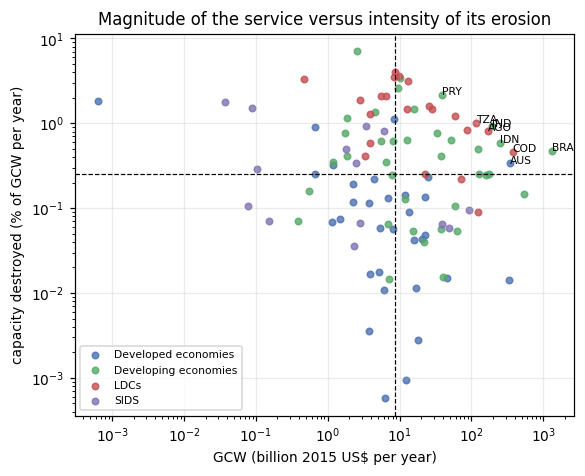

In [21]:
t = r3.dropna(subset=["gcw_usd2015_yr_mean", "erosion_%_du_gcw"]).query(
    "gcw_usd2015_yr_mean > 0 and `erosion_%_du_gcw` > 0")
med_gcw, med_ero = t["gcw_usd2015_yr_mean"].median(), t["erosion_%_du_gcw"].median()
t = t.assign(ampleur=np.where(t["gcw_usd2015_yr_mean"] >= med_gcw, "grand service", "petit service"),
             intensite=np.where(t["erosion_%_du_gcw"] >= med_ero, "érosion forte", "érosion faible"))
t["typologie"] = t["ampleur"] + " / " + t["intensite"]
display(t["typologie"].value_counts().to_frame("nombre de pays"))
rho, p = stats.spearmanr(t["gcw_usd2015_yr_mean"], t["erosion_%_du_gcw"])
print(f"Spearman service ~ intensité d'érosion : rho = {rho:.2f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(5.4, 4.4))
for g_, d in t.groupby("groups"):
    ax.scatter(d["gcw_usd2015_yr_mean"] / 1e9, d["erosion_%_du_gcw"], s=18, alpha=0.8,
               color=GROUP_COLORS.get(g_, "grey"), label=g_)
for _, row in t.nlargest(8, "loss_usd_mean").iterrows():
    ax.annotate(row["iso3"], (row["gcw_usd2015_yr_mean"] / 1e9, row["erosion_%_du_gcw"]), fontsize=7)
ax.axvline(med_gcw / 1e9, color="k", ls="--", lw=0.8); ax.axhline(med_ero, color="k", ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("GCW (billion 2015 US$ per year)"); ax.set_ylabel("capacity destroyed (% of GCW per year)")
ax.set_title("Magnitude of the service versus intensity of its erosion"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R3_typologie.png"); plt.show()

### R3.6 Tendance de la déforestation

Pente de Theil-Sen et test de Mann-Kendall sur les intervalles FRA.
**Cinq points seulement** : la puissance est faible, le résultat reste indicatif.

In [22]:
mid = {"1990-2000": 1995, "2000-2010": 2005, "2010-2015": 2012.5, "2015-2020": 2017.5, "2020-2025": 2022.5}
years = np.array(list(mid.values()), dtype="float64")


def mann_kendall(y):
    y = np.asarray(y, dtype="float64")
    n = y.size
    s = sum(np.sign(y[j] - y[i]) for i in range(n - 1) for j in range(i + 1, n))
    var = n * (n - 1) * (2 * n + 5) / 18
    z = (s - np.sign(s)) / np.sqrt(var) if s != 0 else 0.0
    return s, 2 * (1 - stats.norm.cdf(abs(z)))


world_series = defor[INTERVALS].sum()
slope, _, lo, hi = stats.theilslopes(world_series.to_numpy(), years)
s, p = mann_kendall(world_series.to_numpy())
print(world_series.round(0).to_string())
print(f"\nmonde : Theil-Sen = {slope:.1f} kha/an par an [{lo:.1f}, {hi:.1f}] ; Mann-Kendall S = {s}, p = {p:.2f}")

rows = []
for _, r in defor.nlargest(10, "defor_kha_yr").iterrows():
    y = r[INTERVALS].to_numpy(dtype="float64")
    if np.isnan(y).any():
        continue
    rows.append({"pays": r["name"], "pente (kha/an par an)": stats.theilslopes(y, years)[0],
                 "S": mann_kendall(y)[0], "p": mann_kendall(y)[1]})
display(pd.DataFrame(rows).round(3))

1990-2000    15819.0
2000-2010    13329.0
2010-2015     9878.0
2015-2020     9478.0
2020-2025     8484.0

monde : Theil-Sen = -271.8 kha/an par an [-460.1, -80.1] ; Mann-Kendall S = -10.0, p = 0.03


,pays,pente (kha/an par an),S,p
0,Brazil,-128.306,-4.0,0.462
1,India,3.885,2.0,0.806
2,Democratic Republic of the Congo,-15.825,-4.0,0.462
3,Indonesia,-59.094,-10.0,0.027
4,United Republic of Tanzania,2.667,6.0,0.221
5,China,-0.670,0.0,1.000
6,Paraguay,-7.253,-9.0,0.050
7,Sudan,-0.345,-6.0,0.221


### R3.7 La figure en barres, largeur proportionnelle à l'érosion

Variante de la figure de R2 : la largeur de chaque barre est l'intensité d'érosion, c'est-à-dire la part
du GCW national détruite chaque année. Les pays qui ne déclarent pas leur déforestation sortent du panneau,
car une largeur minimale les ferait passer pour peu érodés (C26, C27).

exclus, érosion non déclarée : USA, JPN, PER


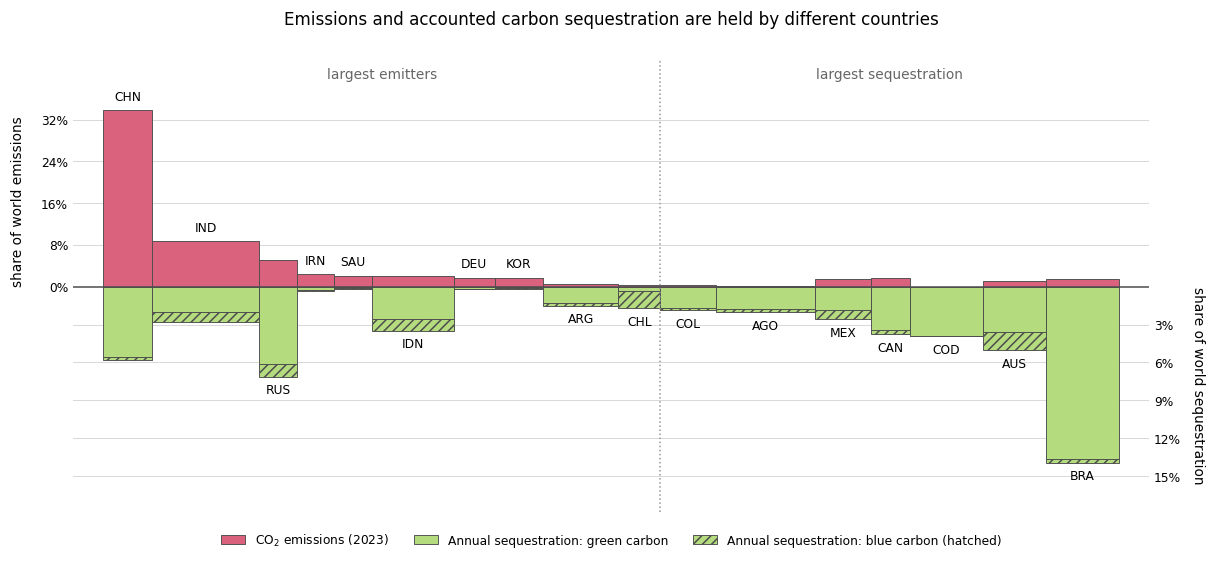

In [23]:
erosion_rate = r3.set_index("iso3")["erosion_%_du_gcw"]
bar_updown(panel, width_metric="erosion", fname="R3_bars_updown_erosion.png")

## R4 - Le coût de la compensation (C24)

Un puits perdu doit être remplacé par de l'abattement si l'objectif climatique est maintenu.
La tonne perdue reçoit alors **deux prix** :

- le **GSCC** (559,6 US$2015/tCO₂) : le dommage évité, donc la valeur de bien-être perdue ;
- un **prix carbone de scénario AR6** : ce qu'il en coûte de la remplacer.

In [24]:
# TODO (C24) : remplacer par les prix de la base de scénarios AR6 du GIEC
# (préciser scénario, année et conversion en dollars constants de 2015).
AR6_PRICES = {"placeholder_bas": 50.0, "placeholder_central": 150.0, "placeholder_haut": 400.0}

lost_tco2 = np.nansum(loss_tco2, axis=0).mean()
value_lost = np.nansum(loss_usd, axis=0).mean()
rows = [{"scénario": k, "prix (US$/tCO2)": v,
         "coût annuel de compensation": usd(lost_tco2 * v, "B"),
         "coût / valeur perdue": lost_tco2 * v / value_lost} for k, v in AR6_PRICES.items()]
display(pd.DataFrame(rows).round(3))
print("capacité perdue chaque année :", f"{lost_tco2 / 1e6:.1f} MtCO2/an")
print("valeur de bien-être perdue (GSCC) :", usd(value_lost, "B"))

,scénario,prix (US$/tCO2),coût annuel de compensation,coût / valeur perdue
0,placeholder_bas,50.0,2.29 B$,0.089
1,placeholder_central,150.0,6.88 B$,0.268
2,placeholder_haut,400.0,18.36 B$,0.714


capacité perdue chaque année : 45.9 MtCO2/an
valeur de bien-être perdue (GSCC) : 25.70 B$


### R4.1 Une perte récurrente

La capacité détruite cette année doit être compensée cette année **et toutes les suivantes** :
une seule année de déforestation crée un flux de coût perpétuel.

In [25]:
PRICE = AR6_PRICES["placeholder_central"]
annual_cost = lost_tco2 * PRICE
print("coût de compensation d'une année de déforestation :", usd(annual_cost, "B"), "par an, indéfiniment")
print(f"valeur actualisée à {DISCOUNT:.0%} :", usd(annual_cost / DISCOUNT))
print("après 10 ans au même rythme, effort annuel supplémentaire :",
      f"{10 * lost_tco2 / 1e6:.0f} MtCO2/an, soit", usd(10 * annual_cost, "B"), "par an")

coût de compensation d'une année de déforestation : 6.88 B$ par an, indéfiniment
valeur actualisée à 2% : 0.34 T$
après 10 ans au même rythme, effort annuel supplémentaire : 459 MtCO2/an, soit 68.85 B$ par an


### R4.2 Qui perd, qui paie

Sans courbes de coût marginal, on ne modélise pas un marché : on compare deux **règles d'allocation**.

1. **Sans échange** : chaque pays compense ses propres pertes.
2. **Effort mondial partagé** : le coût total est réparti au prorata du PIB.

`TODO` : brancher de vraies courbes de coût marginal (Favero & Austin, ou DART) pour un régime de marché,
où les tonnes les moins chères sont abattues d'abord.

,cost_national,cost_shared,écart (Md$)
groups,,,
Developed economies,0.40 B$,2.84 B$,-2.4
Developing economies,3.94 B$,3.77 B$,0.2
LDCs,2.39 B$,0.11 B$,2.3
SIDS,0.07 B$,0.08 B$,-0.0


Gini des pertes : 0.853 | Gini de la charge partagée : 0.827


,name,groups,cost_national,cost_national_share_of_gdp
20,Central African Republic,LDCs,0.03 B$,1.442
49,Somalia,LDCs,0.11 B$,1.207
26,Mozambique,LDCs,0.19 B$,0.949
107,Chad,LDCs,0.09 B$,0.850
5,Democratic Republic of the Congo,LDCs,0.47 B$,0.824
51,Madagascar,LDCs,0.11 B$,0.804
63,Mali,LDCs,0.11 B$,0.621
110,Burkina Faso,LDCs,0.09 B$,0.545
47,Paraguay,Developing economies,0.22 B$,0.507
31,Sudan,LDCs,0.19 B$,0.461


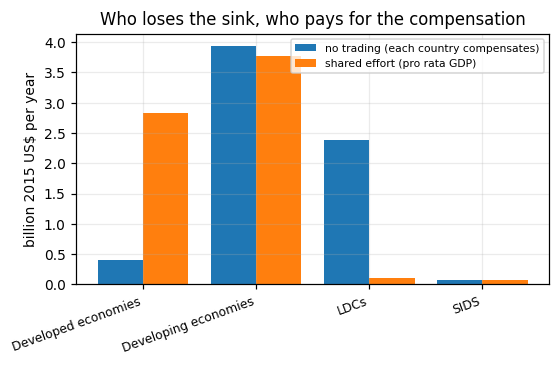

In [26]:
alloc = r3.dropna(subset=["loss_tco2_mean", "gdp"]).copy()
alloc["cost_national"] = alloc["loss_tco2_mean"] * PRICE
alloc["cost_shared"] = alloc["cost_national"].sum() * alloc["gdp"] / alloc["gdp"].sum()
alloc["cost_national_share_of_gdp"] = 100 * alloc["cost_national"] / alloc["gdp"]

by_grp = alloc.groupby("groups")[["cost_national", "cost_shared"]].sum().reindex(GROUP_ORDER)
by_grp["écart (Md$)"] = (by_grp["cost_national"] - by_grp["cost_shared"]) / 1e9
display(by_grp.assign(**{c: by_grp[c].map(lambda v: usd(v, "B")) for c in ["cost_national", "cost_shared"]}).round(1))
print(f"Gini des pertes : {gini(alloc['loss_tco2_mean']):.3f} |",
      f"Gini de la charge partagée : {gini(alloc['cost_shared']):.3f}")
display(alloc.nlargest(10, "cost_national_share_of_gdp")[
    ["name", "groups", "cost_national", "cost_national_share_of_gdp"]]
    .assign(cost_national=lambda d: d["cost_national"].map(lambda v: usd(v, "B"))).round(3))

fig, ax = plt.subplots(figsize=(5.2, 3.4))
idx = np.arange(len(by_grp))
ax.bar(idx - 0.2, by_grp["cost_national"] / 1e9, 0.4, label="no trading (each country compensates)")
ax.bar(idx + 0.2, by_grp["cost_shared"] / 1e9, 0.4, label="shared effort (pro rata GDP)")
ax.set_xticks(idx); ax.set_xticklabels(by_grp.index, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("billion 2015 US$ per year"); ax.legend(fontsize=7)
ax.set_title("Who loses the sink, who pays for the compensation")
fig.tight_layout(); fig.savefig(FIG / "R4_qui_paie.png"); plt.show()

### R4.3 Scénarios d'affaiblissement du puits océanique

Le BCW n'a pas de pertes observées : on applique les scénarios de Rickels et al. (2024), −5 % et −10 %.

In [27]:
rows = []
for pct in (0.05, 0.10):
    ocean_tco2 = (np.nansum(D_BCW, axis=0) / GSCC).mean() * pct
    rows.append({"scénario": f"puits océanique −{pct:.0%}",
                 "tonnes perdues (MtCO2/an)": ocean_tco2 / 1e6,
                 "valeur perdue (GSCC)": usd(ocean_tco2 * GSCC.mean(), "B"),
                 "coût de compensation": usd(ocean_tco2 * PRICE, "B")})
rows.append({"scénario": "déforestation observée (une année)",
             "tonnes perdues (MtCO2/an)": lost_tco2 / 1e6,
             "valeur perdue (GSCC)": usd(value_lost, "B"),
             "coût de compensation": usd(annual_cost, "B")})
display(pd.DataFrame(rows).round(1))

,scénario,tonnes perdues (MtCO2/an),valeur perdue (GSCC),coût de compensation
0,puits océanique −5%,208.3,116.54 B$,31.24 B$
1,puits océanique −10%,416.5,233.09 B$,62.48 B$
2,déforestation observée (une année),45.9,25.70 B$,6.88 B$


## Annexes

Indicateurs par habitant, conservés pour la continuité avec BCW et le commentaire n°18 (C22),
puis contrôle de sensibilité sur les mangroves.

In [28]:
ann = base.dropna(subset=["ncw_usd2015_yr_mean"]).copy()
ann["gcw_per_capita"] = ann["gcw_usd2015_yr_mean"] / ann["population"]
ann["ncw_per_capita"] = ann["ncw_usd2015_yr_mean"] / ann["population"]
ann = ann.merge(r3[["iso3", "loss_usd_mean"]], on="iso3", how="left")
ann["loss_per_capita"] = ann["loss_usd_mean"] / ann["population"]

print("NCW par habitant, moyenne pondérée par la population :",
      f"{ann['ncw_usd2015_yr_mean'].sum() / ann['population'].sum():,.0f} US$2015")
print(f"moyenne non pondérée entre pays : {ann['ncw_per_capita'].mean():,.0f} US$2015")
display(ann.nlargest(15, "ncw_per_capita")[["name", "groups", "gcw_per_capita", "ncw_per_capita"]].round(0))
display(ann.groupby("groups")[["gcw_per_capita", "ncw_per_capita", "loss_per_capita"]].median().round(1))
ann[["iso3", "name", "groups", "gcw_per_capita", "ncw_per_capita", "loss_per_capita"]].to_csv(
    OUT / "tables" / "annexe_per_capita.csv", index=False)

NCW par habitant, moyenne pondérée par la population : 1,298 US$2015
moyenne non pondérée entre pays : 20,308 US$2015


,name,groups,gcw_per_capita,ncw_per_capita
106,Cook Islands,SIDS,2962.0,689179.0
174,Niue,SIDS,28059.0,609549.0
131,Tuvalu,SIDS,278.0,490950.0
81,Marshall Islands,SIDS,665.0,474161.0
135,Naoero,SIDS,0.0,347838.0
127,Palau,SIDS,6381.0,318774.0
54,Seychelles,SIDS,514.0,273130.0
62,Micronesia (Federated States of),SIDS,1306.0,262947.0
37,Kiribati,SIDS,0.0,133875.0
46,Bahamas,SIDS,2488.0,98843.0


,gcw_per_capita,ncw_per_capita,loss_per_capita
groups,,,
Developed economies,462.4,840.2,0.2
Developing economies,471.2,932.9,1.3
LDCs,710.8,1127.8,13.2
SIDS,637.7,5262.4,1.6


In [30]:
# Sensibilité : mangroves retirées du BCW au lieu du GCW (C7, variante conservée)
sens = base.dropna(subset=["ncw_alt_mangroves_usd2015_yr_mean"])
delta = sens["ncw_alt_mangroves_usd2015_yr_mean"].sum() - sens["ncw_usd2015_yr_mean"].sum()
print("NCW mondial, variante mangroves :", usd(sens["ncw_alt_mangroves_usd2015_yr_mean"].sum()),
      "| écart :", usd(delta, "B"))

NCW mondial, variante mangroves : 10.47 T$ | écart : -14.89 B$


## Points restés ouverts

| Sujet | Où | Ce qu'il faut |
|---|---|---|
| Émissions de CO₂ de la table BCW | R2 | Savoir si elles incluent l'usage des terres (double compte avec R3) |
| Seuil de tension de dette | R2.3 | Reprendre la valeur de la Fig. 5c de BCW |
| Seuil vert / bleu / mixte | R2.1 | Valider 2/3 ou un autre seuil |
| Tirages des taux pour les pertes | R3.2 | Les déplacer dans le pipeline pour partager les tirages du GCW (C8, C15) |
| Répartition des hectares déboisés entre biomes | R3.2 | Documenter l'hypothèse ou pondérer vers le tropical |
| Prix AR6 | R4 | Récupérer les prix réels : scénario, année, dollars 2015 (C24) |
| Courbes de coût marginal | R4.2 | Favero & Austin ou DART, pour un vrai régime de marché |
| Taux d'actualisation | R3.4, R4.1 | Uniquement pour capitaliser une série, à trancher |